In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import (
    find_limit_cycle,
    floquet,
    isochron_foliation,
    IsochronSettings,
)
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    1
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# The limit cycle of FitzHugh–Nagumo and its Floquet multipliers

O1 (`find_limit_cycle`) and O2 (`floquet`); the prototyping code that preceded them lives in `tests/test_analysis_ode.py` and `analysis/ode/floquet.py`.

In [2]:
ode = FitzhughNagumo()
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)
cycle.period, cycle.orientation()

(Array(11.22788676, dtype=float64), -1)

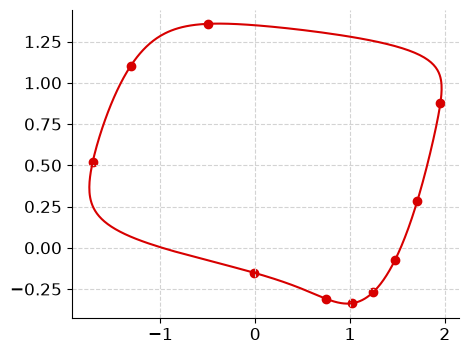

In [3]:
times, points = cycle.sample(512)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*points.T)
ax.scatter(*cycle.x0s.T)

In [4]:
for method in ("periodic_schur", "monodromy", "liouville"):
    fl = floquet(cycle, method=method)
    print(method, fl.multipliers, fl.exponents, fl.trivial_error, fl.closure)

periodic_schur [1.00000000e+00 1.69059036e-12] [ 5.39080812e-11 -2.41416251e+00] 6.05273831055797e-10 2.6581664292158038e-11
monodromy [1.00000000e+00 1.69042558e-12] [ 5.31331915e-11 -2.41417119e+00] 5.965734573010195e-10 None
liouville [1.00000000e+00 1.69059036e-12] [ 0.         -2.41416251] None None


In [ ]:
isochrons = isochron_foliation(
    cycle,
    jnp.linspace(-0.9 * jnp.pi, 0.9 * jnp.pi, 1, endpoint=False),
    settings=IsochronSettings(box_Scale=2.5),
)

In [4]:
isochrons

IsochronFoliation(cycle=LimitCycle(
  ode=FitzhughNagumo(),
  x0s=f64[10,2],
  period=f64[],
  residual=f64[],
  settle=FixedPoint(
    x=f64[2], tau=weak_f64[], k=1, contraction=weak_f64[], converged=True
  ),
  section=CrossSection(point=f64[2], normal=f64[2]),
  config=SolverConfig(
    solver=Dopri8(),
    rtol=1e-10,
    atol=1e-12,
    max_steps=65536,
    adjoint=ForwardMode()
  )
), isochrons=(Isochron(phase=-2.827433388230814, base_point=array([ 1.35963543, -0.1890225 ]), points=array([[ 9.06783992e-01, -2.58375060e-01],
       [ 9.06781207e-01, -2.58375259e-01],
       [ 9.06778226e-01, -2.58375464e-01],
       ...,
       [ 9.33423536e+00,  6.56087945e-03],
       [ 9.38809012e+00,  6.74752817e-03],
       [ 9.39644771e+00,  6.77630881e-03]], shape=(7215, 2)), eta=array([-1.00000000e-06, -9.85876348e-07, -9.71035927e-07, ...,
       -3.56450430e-14, -3.55899367e-14, -3.51511234e-14], shape=(7215,)), arclength=array([-2.51716635, -2.51716355, -2.51716056, ...,  7.98205435,
  

(-3.0, 3.0)

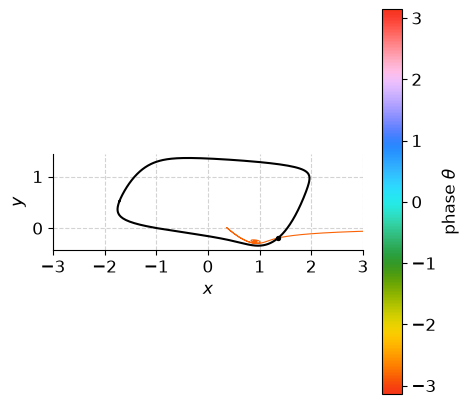

In [6]:
from deep_isochron.plotting import plot_isochrons


fig = plot_isochrons(isochrons)
fig.axes[0].set_xlim(-3, 3)